# 10 · Reproduction

**Question.** Does the standard form, built as printed, reproduce Wu et al. (arXiv:2504.13174): the printed scale factors η_e and the figures at the printed resolution?

In [1]:
from pathlib import Path

from IPython.display import Markdown, display

from pihm import plotting
from pihm.pipeline.results import Results

results = Results.at(Path("..").resolve())
CAMPAIGNS = ("p2_reproduction",)
plotting.apply_style()
print(results.describe(CAMPAIGNS))

p2_reproduction: 327 records, 327 ok


In [2]:
from decimal import Decimal

rows = results.rows("p2_reproduction")
ROOT = results.directory("p2_reproduction")
panels = plotting.scale_factor_rows(rows)


def unit(printed):
    """Return one unit of the printed value's last digit."""
    return 10.0 ** Decimal(repr(printed)).as_tuple().exponent


lines = []
for name, figures in (("The ODE panels", "345"), ("The PDE and nonlinear panels", "67")):
    chosen = [p for p in panels if p["figure"][0] in figures]
    within = [p for p in chosen if abs(p["ideal"] - p["printed"]) <= 1.0000001 * unit(p["printed"])]
    rounded = [p for p in within if abs(p["ideal"] - p["printed"]) <= 0.5 * unit(p["printed"])]
    off = ", ".join(p["figure"] for p in chosen if p not in within)
    lines.append(
        f"- {name} (Figs {', '.join(figures)}): {len(within)} of {len(chosen)} printed η_e agree "
        f"with the exact solution's ‖b‖² to one unit of the last printed digit, {len(rounded)} "
        f"when rounded" + (f"; not reproduced: {off}." if off else ".")
    )
display(Markdown("\n".join(lines)))

- The ODE panels (Figs 3, 4, 5): 11 of 11 printed η_e agree with the exact solution's ‖b‖² to one unit of the last printed digit, 9 when rounded.
- The PDE and nonlinear panels (Figs 6, 7): 0 of 5 printed η_e agree with the exact solution's ‖b‖² to one unit of the last printed digit, 0 when rounded; not reproduced: 6b, 6d, 6f, 7b, 7c.

The printed scale factors beside the exact solution's ‖b‖² (ideal) and the ground state read out
at the regular point, in both variants, at the printed n.

In [3]:
display(
    Markdown(
        plotting.markdown_table(
            panels,
            [
                ("figure", "Fig.", ""),
                ("problem", "panel", ""),
                ("n", "n", "d"),
                ("printed", "printed η_e", ""),
                ("ideal", "ideal ‖b‖²", ".5f"),
                ("faithful", "faithful", ".5f"),
                ("corrected", "corrected", ".5f"),
                ("trusted", "faithful trusted", "flag"),
            ],
        )
    )
)

| Fig. | panel | n | printed η_e | ideal ‖b‖² | faithful | corrected | faithful trusted |
|---|---|---|---|---|---|---|---|
| 3b | R2a | 3 | 1.29 | 1.29009 | 1.28731 | 1.28731 | yes |
| 3c | R2b | 3 | 32.47 | 32.47741 | 32.22636 | 32.22636 | no |
| 3d | R2c | 5 | 451.71 | 451.70962 | 451.52312 | 451.52312 | yes |
| 4a | R3a | 3 | 1.75 | 1.74512 | 1.74512 | 1.74512 | yes |
| 4b | R3b | 3 | 1.49 | 1.48779 | 1.48779 | 1.48779 | yes |
| 4c | R3c | 5 | 108.51 | 108.51142 | 109.70433 | 1472.16797 | no |
| 4d | R3d | 5 | 135.38 | 135.38360 | 137.46159 | 2417.74805 | no |
| 5a | R4a | 3 | 1.35 | 1.34649 | 1.34478 | 1.34649 | yes |
| 5b | R4b | 3 | 14.74 | 14.74797 | 14.72531 | 14.72357 | yes |
| 5c | R4c | 4 | 0.82 | 0.82116 | 0.82521 | 0.82116 | yes |
| 5d | R4d | 4 | 77.51 | 77.51167 | 76.93737 | 77.51169 | yes |
| 6b | R5a | 3 | 5.21559 | 5.21653 | 5.24407 | 5.21740 | yes |
| 6d | R5b | 4 | 603.863 | 598.86606 | 598.87966 | 598.86527 | yes |
| 6f | R5c | 5 | 216.469 | 239.82712 | 239.82712 | 239.82712 | yes |
| 7b | R6a | 2 | 3.75367 | 3.52344 | 3.52344 | 3.52344 | no |
| 7c | R6b | 2 | 0.07984 | 0.04383 | 0.04182 | 0.04182 | no |

The paper's figures rebuilt at the printed n: the exact solution in ink, the faithful variant (as
printed) and the corrected one, each with its error; Fig. 6 as error maps, and Fig. 7 in the
doubled space, read out as the product state of least residual.

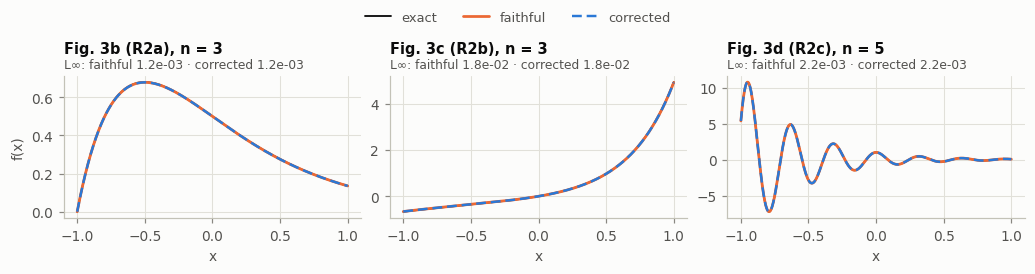

In [4]:
plotting.solution_panels(rows, ROOT, ["R2a", "R2b", "R2c"], columns=3);

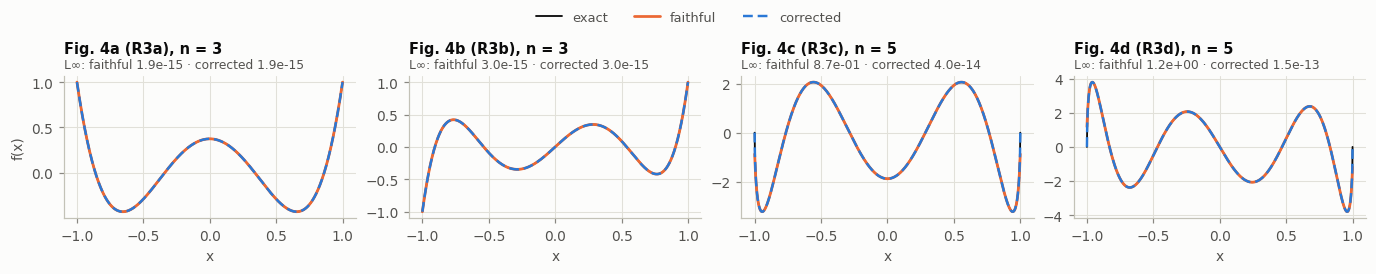

In [5]:
plotting.solution_panels(rows, ROOT, ["R3a", "R3b", "R3c", "R3d"]);

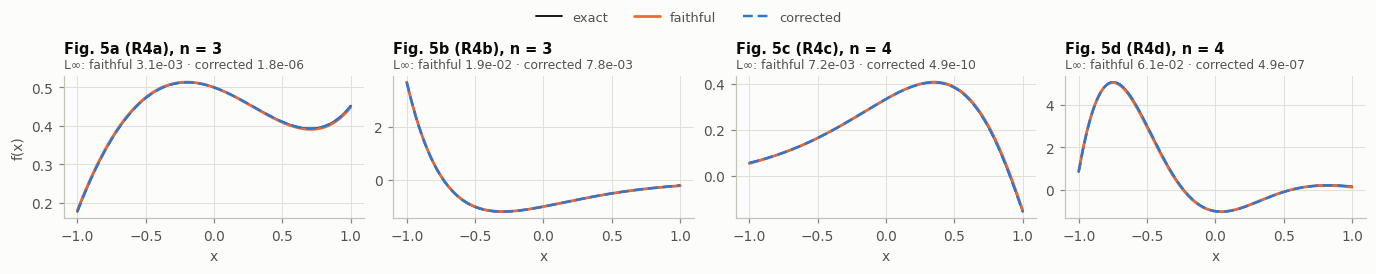

In [6]:
plotting.solution_panels(rows, ROOT, ["R4a", "R4b", "R4c", "R4d"]);

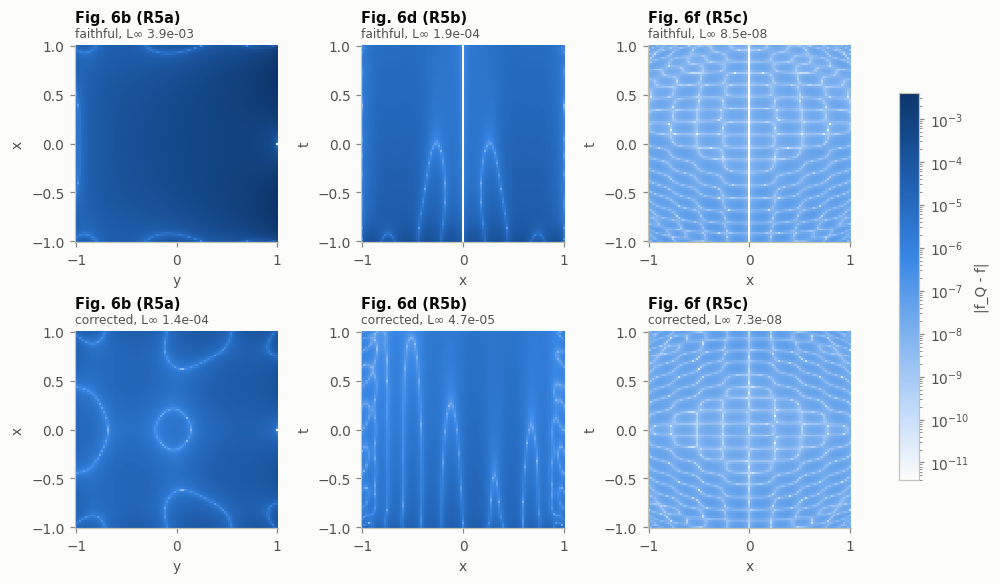

In [7]:
plotting.error_maps(rows, ROOT, ["R5a", "R5b", "R5c"]);

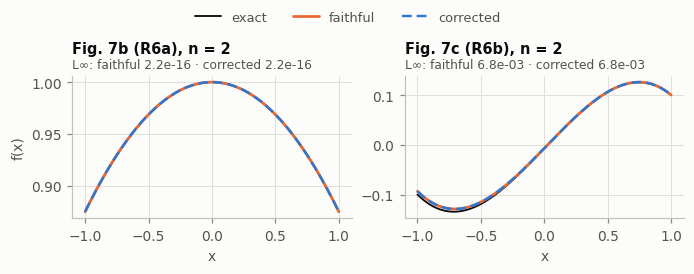

In [8]:
plotting.solution_panels(rows, ROOT, ["R6a", "R6b"], columns=2);

**What this does not show.** These are classical ground states; the quantum preparation is
notebooks 30–34's. Why the faithful variants fall short, and what the corrections change, is
notebook 11's.